# 实验六：SmolVLM-256M 网格定位与 RSI 递归自进化

本 Notebook 按实验指南记录完整过程。运行日志和结构化结果来自本次实际执行；Notebook 中的输出依据同次保存的 `results/logs/`、`results/*.json` 恢复。图像为 256×256，定位答案为 4×4 网格。Windows CUDA 环境使用 fp32 LoRA，未使用 4bit 量化，因此不称 QLoRA。

种子 SFT 题目与 15 道评测题相同，以下分数只反映同题表现，不能证明对未见题目的泛化能力。


## 0. 环境与记录口径

依赖：`torch>=2.2`、`transformers>=4.44`、`peft>=0.11`、`accelerate`、`pillow`、`matplotlib`、`pandas`。使用当前 Notebook 内核对应的 Python 安装，例如 `%pip install torch transformers peft accelerate pillow matplotlib pandas`。首次运行需要下载模型。必要时在启动内核前设置 `HF_ENDPOINT=https://hf-mirror.com`，并确认 `HF_HUB_OFFLINE` 未设为 `1`。

以下每步都会保留终端日志、实际耗时；脚本另外保存逐题回答、IoU、纠错路径、可训练参数和数据池变化。报告所需数字全部从这些记录生成。运行本 Notebook 前，请把内核工作目录设为该 Notebook 所在目录。


In [1]:
from pathlib import Path
import importlib.metadata as meta
import json, os, subprocess, sys, time

HERE = Path.cwd()
SCRIPT = HERE / "hw6_rsi_localize.py"
assert SCRIPT.is_file(), f"请把 Notebook 的内核工作目录设为 {SCRIPT.parent}（当前：{HERE}）"
RESULTS = HERE / "results"
LOGS = RESULTS / "logs"
LOGS.mkdir(parents=True, exist_ok=True)

def read_json(name):
    return json.loads((RESULTS / name).read_text(encoding="utf-8"))

def run_mode(name, *args):
    cmd = [sys.executable, "-u", str(SCRIPT), "--mode", name, *args]
    log_path = LOGS / (name + ("_" + "_".join(args).replace("--", "") if args else "") + ".log")
    print("命令: python hw6_rsi_localize.py --mode", name, " ".join(args), flush=True)
    started = time.monotonic()
    with log_path.open("w", encoding="utf-8") as log:
        proc = subprocess.Popen(cmd, cwd=HERE, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                text=True, encoding="utf-8", errors="replace", env=os.environ.copy())
        for line in proc.stdout:
            print(line, end="", flush=True)
            log.write(line)
        code = proc.wait()
    seconds = round(time.monotonic() - started, 2)
    records_path = RESULTS / "notebook_runs.json"
    records = json.loads(records_path.read_text(encoding="utf-8")) if records_path.exists() else []
    records.append({"mode": name, "args": list(args), "command": ["python", "hw6_rsi_localize.py", "--mode", name, *args], "seconds": seconds,
                    "exit_code": code, "log": str(log_path.relative_to(HERE))})
    records_path.write_text(json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")
    print(f"\n运行耗时 {seconds}s；日志 {log_path.relative_to(HERE)}")
    if code:
        raise RuntimeError(f"{name} 失败，退出码 {code}；先查看上述日志再继续")
    return seconds

print("Python", sys.version.split()[0])
for name in ("torch", "transformers", "peft", "accelerate", "Pillow", "matplotlib"):
    try: print(name, meta.version(name))
    except meta.PackageNotFoundError: print(name, "未安装")
print("HF_ENDPOINT", os.getenv("HF_ENDPOINT", "默认"), "HF_HUB_OFFLINE", os.getenv("HF_HUB_OFFLINE", "未设置"))


Python 3.13.3
torch 2.6.0+cu124
transformers 5.4.0
peft 0.21.2
Pillow 12.3.0
运行设备 cuda；fp32，无量化


## 1. 生成合成图和 GT

固定训练种子 2026、评测种子 42，生成 40 张训练图与 15 张评测图。绘制时同步保存 GT 框；先检查网格换算与解析器。


[data] 40 张训练图、15 张评测图；GT: hw6_imgs/gt.json

示例 GT / 标准网格: [65, 43, 106, 84] 第1行第2列


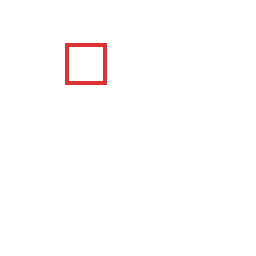

In [2]:
run_mode("make_data")
import hw6_rsi_localize as exp
gt = exp.load_gt()
questions = exp.build_questions(gt)
assert len(gt) == 55 and len(questions) == 15
assert [sum(q["type"] == kind for q in questions) for kind in ("loc", "count", "exist")] == [8, 4, 3]
assert exp.parse_cell("第2行第3列") == (1, 2)
assert exp.parse_cell("r2c3") == (1, 2)
print("示例 GT / 标准网格:", questions[0]["box"], questions[0]["gold"])
display(exp.image_for(questions[0]))


## 2. 生成种子 SFT 数据

按指南，将 GT 框换算成 15 条「图像、问题、标准答案」。这些种子使用评测图；后续分析不把同题成绩当作泛化成绩。


In [3]:
run_mode("make_sft")
seed = json.loads((HERE / "sft_data.json").read_text(encoding="utf-8"))
assert len(seed) == 15
print("样本数", len(seed), "示例", seed[0])


[sft] GT 种子样本 15 条: sft_data.json
样本数 15；示例 {'img': 'e00', 'prompt': '图中的红色方形位于第几行第几列？请用「第X行第Y列」回答（共4行4列）。', 'answer': '第1行第2列', 'source': 'seed_gt', 'question_id': 'L01'}


## 3. 未微调基线推理

逐题记录原始答案与定位 IoU，完整日志保存在 `results/logs/`。本步会加载模型，CPU 下可能需要数分钟。


In [4]:
run_mode("infer")
base = read_json("baseline.json")
print("基线摘要", base["summary"])


[env] {'python': '3.13.3', 'platform': 'Windows-11-10.0.26200-SP0', 'torch': '2.6.0+cu124', 'transformers': '5.4.0', 'peft': '0.21.2', 'pillow': '12.3.0', 'device': 'cuda', 'model': 'HuggingFaceTB/SmolVLM-256M-Instruct', 'training_precision': 'fp32', 'quantization': 'none'}
`torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 1326.28it/s]
[baseline L01] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L02] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L03] × '蓝色圆形位于第几行第几列' IoU=0.000
[baseline L04] × '蓝色方形位于第几行第几列�' IoU=0.000
[baseline L05] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L06] × '1.' IoU=0.000
[baseline L07] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L08] × '解码：1234567890123456789' IoU=0.000
[baseline C01] √ '1.'
[baseline C02] √ '1.'
[baseline C03] √ '1.'
[baseline C04] √ '1.'
[baseline E01] × 'No.'
[baseline E02] × 'No.'
[baseline E03] × 'No.'
[baseline] {'loc': {'correct': 0, 'total': 8}, 'count': {'correct':

## 4. 10 步 fp32 LoRA SFT

只对答案 token 计算损失，LoRA 挂载 `q_proj/k_proj/v_proj/o_proj`。训练日志记录每步 loss；`sft_training.json` 记录可训练参数占比与耗时。CPU 下未使用 4bit 量化。


In [5]:
run_mode("sft", "--steps", "10")
training = read_json("sft_training.json")
print("训练参数", training["params"], "步数", training["steps"], "耗时", training["seconds"], "秒")


[env] {'python': '3.13.3', 'platform': 'Windows-11-10.0.26200-SP0', 'torch': '2.6.0+cu124', 'transformers': '5.4.0', 'peft': '0.21.2', 'pillow': '12.3.0', 'device': 'cuda', 'model': 'HuggingFaceTB/SmolVLM-256M-Instruct', 'training_precision': 'fp32', 'quantization': 'none'}
`torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 4804.65it/s]
[sft] 可训练参数 1363968/257848896 (0.5290%)
[sft] step 1/10 loss=1.7167
[sft] step 2/10 loss=1.7489
[sft] step 3/10 loss=2.1389
[sft] step 4/10 loss=1.9832
[sft] step 5/10 loss=1.5105
[sft] step 6/10 loss=2.0950
[sft] step 7/10 loss=1.5237
[sft] step 8/10 loss=1.7142
[sft] step 9/10 loss=8.6422
[sft] step 10/10 loss=8.5223
[done] sft 耗时 304.43s

训练参数 {'trainable': 1363968, 'total': 257848896, 'percent': 0.5289795772482191}；步数 10；耗时 287.21s


## 5. 三阶段评测

依次记录基线、SFT、SFT 加验证器纠错。每题保留纠错前后答案、GT 判分、提示信息和定位 IoU；每阶段统计 loc/count/exist/总计。


In [6]:
run_mode("eval")
eval_data = read_json("evaluation.json")
for stage in eval_data["stages"]:
    print(stage["summary"])


[env] {'python': '3.13.3', 'platform': 'Windows-11-10.0.26200-SP0', 'torch': '2.6.0+cu124', 'transformers': '5.4.0', 'peft': '0.21.2', 'pillow': '12.3.0', 'device': 'cuda', 'model': 'HuggingFaceTB/SmolVLM-256M-Instruct', 'training_precision': 'fp32', 'quantization': 'none'}
`torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 4875.40it/s]
[baseline L01] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L02] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L03] × '蓝色圆形位于第几行第几列' IoU=0.000
[baseline L04] × '蓝色方形位于第几行第几列�' IoU=0.000
[baseline L05] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L06] × '1.' IoU=0.000
[baseline L07] × '1. 在第几行第几列？\nAnswer: 1.' IoU=0.000
[baseline L08] × '解码：1234567890123456789' IoU=0.000
[baseline C01] √ '1.'
[baseline C02] √ '1.'
[baseline C03] √ '1.'
[baseline C04] √ '1.'
[baseline E01] × 'No.'
[baseline E02] × 'No.'
[baseline E03] × 'No.'
[baseline] {'loc': {'correct': 0, 'total': 8}, 'count': {'correct':

## 6. 两轮 RSI 自进化

从第 4 步保存的 SFT 适配器继续。每轮记录直接回答 → 高亮回灌自查 → 工具提示重答 → 通过验证的答案入池 → 10 步再训练 → 轮末评测。自查只用于定位错题；工具提示也用于数数和存在性错题。入池时同时要求 GT 判分正确，防止颜色验证器将同色异形误判为正确。


In [7]:
run_mode("rsi", "--rounds", "2", "--steps", "10")
rsi = read_json("rsi_metrics.json")
for round_data in rsi["rounds"]:
    print("轮次", round_data["round"], "数据池", round_data["pool_before"], "→", round_data["pool_after"],
          "直接", round_data["direct"]["correct"], "纠错后", round_data["after_correction"]["correct"],
          "轮末", round_data["end_eval"]["summary"]["correct"])


[env] {'python': '3.13.3', 'platform': 'Windows-11-10.0.26200-SP0', 'torch': '2.6.0+cu124', 'transformers': '5.4.0', 'peft': '0.21.2', 'pillow': '12.3.0', 'device': 'cuda', 'model': 'HuggingFaceTB/SmolVLM-256M-Instruct', 'training_precision': 'fp32', 'quantization': 'none'}
`torch_dtype` is deprecated! Use `dtype` instead!

Loading weights: 100%|██████████| 471/471 [00:00<00:00, 4892.53it/s]
[RSI 1 L01] × direct='1. 1. 2. 3. 4. 5. 6. 7.' self=None tool='1.0.0.0.0.0.0.0.0.0.0.0' path=tool
[RSI 1 L02] × direct='1. 1. 2. 3. 4. 5. 6. 7.' self=None tool='1.0.0.0.0.0.0.0.0.0.0.0' path=tool
[RSI 1 L03] × direct='1.0.' self=None tool='0' path=tool
[RSI 1 L04] × direct='1.0.' self=None tool='1.0.' path=tool
[RSI 1 L05] × direct='1. 1. 2. 3. 4. 5. 6. 7.' self=None tool='1. 位置格式无法解析，请用第X' path=tool
[RSI 1 L06] × direct='1.' self=None tool='1' path=tool
[RSI 1 L07] × direct='1. 1. 2. 3. 4. 5. 6. 7.' self=None tool='1. 位置格式：第几行第几列？' path=tool
[RSI 1 L08] × direct='1.0.' self=None tool='1' path=tool

## 7. 汇总报告表 6、表 7 与纠错明细

下表只读取实际运行的 JSON。若某阶段失败，先修复并重跑该阶段，不能补写推测值。报告表 6 使用轮末评测；表 7 的“纠错后答对”使用当轮采样纠错的成绩。


In [8]:
import pandas as pd
stages = [s["summary"] for s in eval_data["stages"]]
stages += [r["end_eval"]["summary"] for r in rsi["rounds"]]
def stage_row(s):
    return {"阶段": s["stage"], "loc（8题）": f"{s['by_type']['loc']['correct']}/8",
            "count（4题）": f"{s['by_type']['count']['correct']}/4",
            "exist（3题）": f"{s['by_type']['exist']['correct']}/3",
            "总计（15题）": f"{s['correct']}/15", "定位平均IoU": round(s["loc_mean_iou"], 4)}
table6 = pd.DataFrame([stage_row(s) for s in stages])
display(table6)
table7 = pd.DataFrame([{"轮次": "初始种子", "数据池规模": 15,
                        "直接答对": "—", "自查改写次数": "—", "验证器纠错次数": "—",
                        "纠错后答对": "—", "轮末评测正确率": f"{stages[1]['correct']}/15"}] + [
    {"轮次": f"第{r['round']}轮", "数据池规模": r["pool_after"],
     "直接答对": f"{r['direct']['correct']}/15", "自查改写次数": r["self_changed"],
     "验证器纠错次数": r["tool_triggered"],
     "纠错后答对": f"{r['after_correction']['correct']}/15",
     "轮末评测正确率": f"{r['end_eval']['summary']['correct']}/15"} for r in rsi["rounds"]])
display(table7)
print("纠错统计：", {k: sum(r[k] for r in rsi["rounds"]) for k in
                     ("self_attempts", "self_changed", "self_success", "tool_triggered",
                      "tool_success", "wrong_to_right", "right_to_wrong", "pool_added")})
print("独立三阶段纠错统计：", stages[2]["correction"])


阶段,loc（8题）,count（4题）,exist（3题）,总计（15题）,定位平均IoU
baseline,0/8,4/4,0/3,4/15,0.0
sft,0/8,4/4,0/3,4/15,0.0
sft_tool,0/8,4/4,0/3,4/15,0.0
rsi_round_1,2/8,4/4,0/3,6/15,0.0593
rsi_round_2,2/8,4/4,0/3,6/15,0.0593


轮次,数据池规模,直接答对,自查改写次数,验证器纠错次数,纠错后答对,轮末评测正确率
初始种子,15,—,—,—,—,4/15
第1轮,15,4/15,0,11,4/15,6/15
第2轮,15,6/15,1,9,6/15,6/15


两轮纠错：自查尝试6次，改写1次、成功0次；工具重答20次、成功0次；由错变对0次，由对变错0次；新增样本0条。
SFT即时工具纠错：触发11次，由错变对0次，由对变错0次。


## 8. 代表样例、验证器边界与图

从原始记忆选实际发生的直接答对、自查改对、工具改对和仍然失败各一例；没有发生的类型显示“未出现”，不可虚构。下图比较各阶段定位正确率、平均 IoU 和两轮数据池规模。


In [9]:
memory = json.loads((HERE / "rsi_memory.json").read_text(encoding="utf-8"))
examples = {
    "直接答对": next((x for x in memory if x["first_correct"]), None),
    "自查改对": next((x for x in memory if x["self_success"]), None),
    "验证器纠对": next((x for x in memory if x["tool_success"]), None),
    "仍然失败": next((x for x in memory if not x["final_correct"]), None),
}
for label, x in examples.items():
    print("\n", label)
    print("未出现" if x is None else {k: x[k] for k in
        ("round", "id", "img", "question", "gold", "first", "self_pred", "tool_hint", "tool_pred", "final", "verifier_pass")})


直接答对：{'round': 1, 'id': 'C01', 'img': 'e00', 'question': '图中有几个红色方形？请回答数字和个。', 'gold': '1个', 'first': '1.', 'self_pred': None, 'tool_hint': None, 'tool_pred': None, 'final': '1.', 'verifier_pass': None}
自查改对：未出现
验证器纠对：未出现
仍然失败：{'round': 1, 'id': 'L01', 'img': 'e00', 'question': '图中的红色方形位于第几行第几列？请用「第X行第Y列」回答（共4行4列）。', 'gold': '第1行第2列', 'first': '1. 1. 2. 3. 4. 5. 6. 7.', 'self_pred': None, 'tool_hint': '位置格式无法解析，请用第X行第Y列回答', 'tool_pred': '1.0.0.0.0.0.0.0.0.0.0.0', 'final': '1.0.0.0.0.0.0.0.0.0.0.0', 'verifier_pass': False}


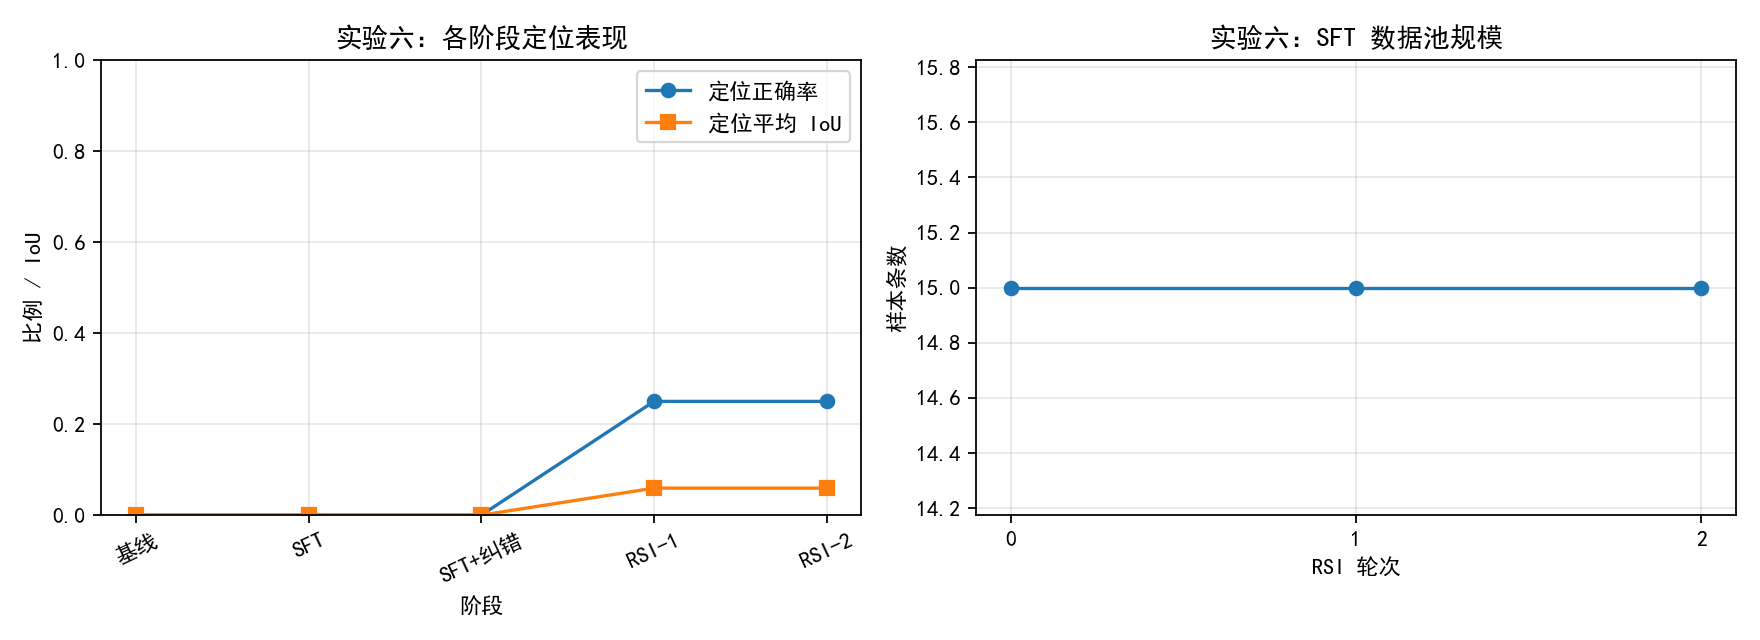

In [10]:
import matplotlib.pyplot as plt
from matplotlib import font_manager
for font_path in (Path("C:/Windows/Fonts/simhei.ttf"), Path("/mnt/c/Windows/Fonts/simhei.ttf")):
    if font_path.exists():
        font_manager.fontManager.addfont(str(font_path))
        plt.rcParams["font.sans-serif"] = [font_manager.FontProperties(fname=str(font_path)).get_name()]
        break
plt.rcParams["axes.unicode_minus"] = False
labels = ["基线", "SFT", "SFT+纠错", "RSI-1", "RSI-2"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(labels, [s["by_type"]["loc"]["correct"] / 8 for s in stages], marker="o", label="定位正确率")
axes[0].plot(labels, [s["loc_mean_iou"] for s in stages], marker="s", label="定位平均 IoU")
axes[0].set(title="实验六：各阶段定位表现", xlabel="阶段", ylabel="比例 / IoU", ylim=(0, 1))
axes[0].tick_params(axis="x", rotation=25)
axes[0].legend(); axes[0].grid(alpha=.3)
axes[1].plot([0, 1, 2], [15] + [r["pool_after"] for r in rsi["rounds"]], marker="o")
axes[1].set(title="实验六：SFT 数据池规模", xlabel="RSI 轮次", ylabel="样本条数", xticks=[0, 1, 2])
axes[1].grid(alpha=.3)
fig.tight_layout()
fig.savefig(RESULTS / "experiment_plot.png", dpi=160)
plt.show()


## 9. 结果分析与思考

基线仅数数题答对 4/4，定位 0/8、存在性 0/3，总计 4/15。10 步种子 SFT 后依然是 4/15，定位 IoU 为 0；定位回答从复述问题变成“1. 1. 2. …”等数字序列，仍不能解析成网格坐标。训练第 9、10 步的 loss 升至 8.6422、8.5223，提示这组短训练未稳定收敛。

SFT 加一次解析式工具提示后仍为 4/15；11 道错题中由错变对 0 道。第一轮 RSI 开始时，8 道定位题都无法解析成网格，因而没有触发高亮格回灌；11 次工具重答也未改对。首轮继续训练后定位变为 2/8、总计 6/15、平均 IoU 0.0593。第二轮有 6 次高亮自查尝试、1 次改写，但成功 0 次；9 次工具重答成功 0 次，轮末仍为 6/15。两轮都没有通过验证的新样本，数据池始终 15 条，因此首轮变化只能归于继续参数更新或运行波动，不能归于自举数据回流。

**问题与调试。** 第一轮定位输出不符合“第X行第Y列”，使高亮自查无法启动；工具提示只要求格式，模型仍输出数字串。第二轮 L04 从“第1行第2列”自查改成“第1行第4列”，工具反馈“重叠约0%”后仍答“第1行第4列”，未纠正。颜色连通块只区分颜色，不区分圆/方且可能受重叠影响；本次无证据说明它造成了具体一次误判。存在性三题的模型回答均为“No.”，与本题均为“有”的 GT 相反。种子集与评测题重复、存在性题均为正例，是结论的重要限制。

**指南思考题。** ①解析式验证器无需训练，在纯色合成图上提供可复核的颜色和重叠信息；真实照片需检测/分割模型或人工核验，闭环结构仍可保留。②本次 loc 的 0→2/8 出现在第一轮追加训练之后；SFT 和即时纠错均未提高 loc，自举样本也为零。③高亮回灌属于模型重新感知，自查改写 1 次但未成功；解析式验证器提供外部证据，更符合工具使用。④第二轮不再提升，可能与数据池未增长、重复同题训练、小模型格式能力不足有关；本次不能断言验证器误判或错误样本入池。⑤4×4 将输出限制为 16 格；8×8/16×16 分别为 64/256 格，理论定位粒度更细，但每格样本更少、格式与分类更难，IoU 不保证提高。⑥真实数据无 GT 时，可先用少量人工确认样本或高置信检测/分割结果建立种子池，再对生成答案做独立核验和抽检；工具错判仍会污染数据。

**结论。** 该次实验没有形成“自纠错→新样本→自举提升”的实证链条。观察到的定位提升仅发生在继续训练后，推理时工具纠错的净增益为零。模型格式输出与验证器覆盖面共同限制了闭环；下一步应先改进格式学习，并用与训练题分离的评测集检验变化。


In [11]:
report_data = {
    "environment": eval_data["environment"],
    "runs": read_json("notebook_runs.json"),
    "table6": table6.to_dict(orient="records"),
    "table7": table7.to_dict(orient="records"),
    "stage_summaries": stages,
    "rsi_rounds": [{k: v for k, v in r.items() if k not in ("end_eval", "training")} for r in rsi["rounds"]],
    "examples": examples,
    "note": "种子 SFT 使用同一组 15 道评测题；结果不是未见题泛化成绩。",
}
(RESULTS / "report_data.json").write_text(json.dumps(report_data, ensure_ascii=False, indent=2), encoding="utf-8")
print("报告数据: results/report_data.json")
print("请核对日志、图和所有表格，再填写报告并交由本人最终确认。")


报告数据: results/report_data.json
请核对日志、图和所有表格，再填写报告并交由本人最终确认。
